### 

<div style="border: 6px solid #18453B; padding: 12px; border-radius: 5px; background:#F7FAF7; color:#1A1A1A;">
<h1 style="color:#18453B; margin-top:0;">CMSE 830 </h1>
<h2 style="margin-bottom:4px;">Midterm Project</h2>
<p style="margin-bottom:0;">Fall 2026</p>
</div>

<div style="background:#F7FAF7; color:#1A1A1A; border:2px solid #18453B; padding:12px; border-radius:5px;">
<h2 style="color:#18453B; margin-top:0;">Student Information</h2>
<p><b>Name:</b> Masoud Moradi</p>
<p><b>Project title:</b> What factors are associated with used-car prices?</p>
<p><b>GitHub repository:</b> https://github.com/masoudm2026/CMSE830</p>
<p><b>Streamlit app:</b> Local URL: http://localhost:8503/</p>
    
<p><b>Preliminary slide file:</b> Masoud Moradi/ https://github.com/masoudm2026/CMSE830</p>
</div>

# Used-Car Price Explorer
## CMSE 830 — Midterm Project

### 1. Project Overview

**Project question:** What characteristics are associated with used-car prices, especially horsepower, engine size, and manufacturer?

**Intended audience:** People interested in comparing used cars and understanding how vehicle characteristics relate to price.

**Project goal:** This project explores the relationship between vehicle specifications and automobile prices using exploratory data analysis (EDA) and data visualization. The analysis focuses on horsepower, engine size, and manufacturer.

**Dataset:** Automobile dataset from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/10/automobile).

**Observation unit:** One row represents one automobile.

**Analytical approach:** I will inspect data quality, examine missing values and unusual observations, visualize price distributions, calculate correlations, and compare prices across manufacturers.

**Important limitation:** The dataset represents automobiles from the 1985 era. The results describe relationships in this historical dataset and should not be interpreted as estimates of current used-car prices. Associations do not establish causation.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Make tables and plots easier to read
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


### 2. Dataset Source and Background

The dataset used in this project is the Automobile dataset from the UCI Machine Learning Repository.

**Source:** https://archive.ics.uci.edu/dataset/10/automobile

The dataset documentation identifies 205 automobile observations and describes vehicle characteristics such as manufacturer, fuel type, body style, horsepower, engine size, and price.

The raw dataset uses `?` to represent missing values. During data loading, these markers will be converted into missing values so that data quality can be examined consistently.

For this analysis, `price` is the outcome variable, while the other vehicle characteristics are potential explanatory variables.

In [2]:

# URL of the raw Automobile dataset
url = ( "https://archive.ics.uci.edu/ml/"  "machine-learning-databases/autos/imports-85.data")

# Column names from the original dataset documentation
columns = [  "symboling", "normalized_losses", "make","fuel_type",  "aspiration", "num_of_doors", "body_style", 
             "drive_wheels", "engine_location", "wheel_base", "length", "width", "height", "curb_weight",
             "engine_type", "num_of_cylinders","engine_size", "fuel_system", "bore", "stroke", "compression_ratio",
             "horsepower", "peak_rpm", "city_mpg", "highway_mpg",  "price"]

# Load the data and convert '?' into missing values
df = pd.read_csv(  url,  names=columns,  na_values="?")

print("Dataset loaded successfully!")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nFirst five rows:")
display(df.head())

Dataset loaded successfully!
Number of rows: 205
Number of columns: 26

First five rows:


,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,length,width,height,curb_weight,engine_type,num_of_cylinders,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


In [3]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               205 non-null    str    
 3   fuel_type          205 non-null    str    
 4   aspiration         205 non-null    str    
 5   num_of_doors       203 non-null    str    
 6   body_style         205 non-null    str    
 7   drive_wheels       205 non-null    str    
 8   engine_location    205 non-null    str    
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    str    
 15  num_of_cylinders   205 non-null    str    
 16  engine_size     

In [4]:
numeric_columns = [ "symboling", "normalized_losses",  "wheel_base", "length", "width", "height", "curb_weight",  "engine_size",
                    "bore", "stroke",  "compression_ratio", "horsepower", "peak_rpm", "city_mpg",  "highway_mpg",  "price"]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Numeric columns converted.")
print(df[numeric_columns].dtypes)

Numeric columns converted.
symboling              int64
normalized_losses    float64
wheel_base           float64
length               float64
width                float64
height               float64
curb_weight            int64
engine_size            int64
bore                 float64
stroke               float64
compression_ratio    float64
horsepower           float64
peak_rpm             float64
city_mpg               int64
highway_mpg            int64
price                float64
dtype: object


In [5]:
missing_summary = pd.DataFrame({ "Missing Count": df.isna().sum(), "Missing Percent": (df.isna().mean() * 100).round(2)})

missing_summary = missing_summary[ missing_summary["Missing Count"] > 0].sort_values("Missing Count", ascending=False)

display(missing_summary)

,Missing Count,Missing Percent
normalized_losses,41,20.00
bore,4,1.95
stroke,4,1.95
price,4,1.95
num_of_doors,2,0.98
horsepower,2,0.98
peak_rpm,2,0.98


In [6]:
duplicate_count = df.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)

Number of exact duplicate rows: 0



### 3. Data Quality and Missing Values

The dataset contains 205 observations and 26 columns. Missing values are represented as `NaN` after loading the original data, where the source uses `?` to indicate unavailable values.

The largest amount of missing data occurs in `normalized_losses`, with 41 missing values (20.00%). The outcome variable, `price`, has 4 missing values (1.95%), while `horsepower` has 2 (0.98%). The dataset contains no exact duplicate rows.

Because different analyses require different variables, missing observations are excluded only from the relevant calculations. For example, the horsepower–price relationship uses observations with valid values for both variables. This approach preserves as much usable data as possible. Missing `price` values are not imputed because price is the outcome variable of interest; analyses requiring a known price exclude those observations.

In [7]:
main_numeric = [ "price", "horsepower", "engine_size", "curb_weight", "city_mpg", "highway_mpg"]

summary_stats = df[main_numeric].describe().T
summary_stats = summary_stats.round(2)

display(summary_stats)

,count,mean,std,min,25%,50%,75%,max
price,201.0,13207.13,7947.07,5118.0,7775.0,10295.0,16500.0,45400.0
horsepower,203.0,104.26,39.71,48.0,70.0,95.0,116.0,288.0
engine_size,205.0,126.91,41.64,61.0,97.0,120.0,141.0,326.0
curb_weight,205.0,2555.57,520.68,1488.0,2145.0,2414.0,2935.0,4066.0
city_mpg,205.0,25.22,6.54,13.0,19.0,24.0,30.0,49.0
highway_mpg,205.0,30.75,6.89,16.0,25.0,30.0,34.0,54.0


In [8]:
variables_to_check = ["price", "horsepower", "engine_size", "curb_weight", "city_mpg"]

nonpositive_counts = ( (df[variables_to_check] <= 0) .sum() .rename("Nonpositive Count") .to_frame())

display(nonpositive_counts)

,Nonpositive Count
price,0
horsepower,0
engine_size,0
curb_weight,0
city_mpg,0


### 4. Distribution of Automobile Prices

The distribution of prices helps us understand the range of values in the dataset and whether a typical price is better represented by the mean or the median. A histogram will show how frequently different price ranges occur. Because four price observations are missing, the histogram will use the available price values.

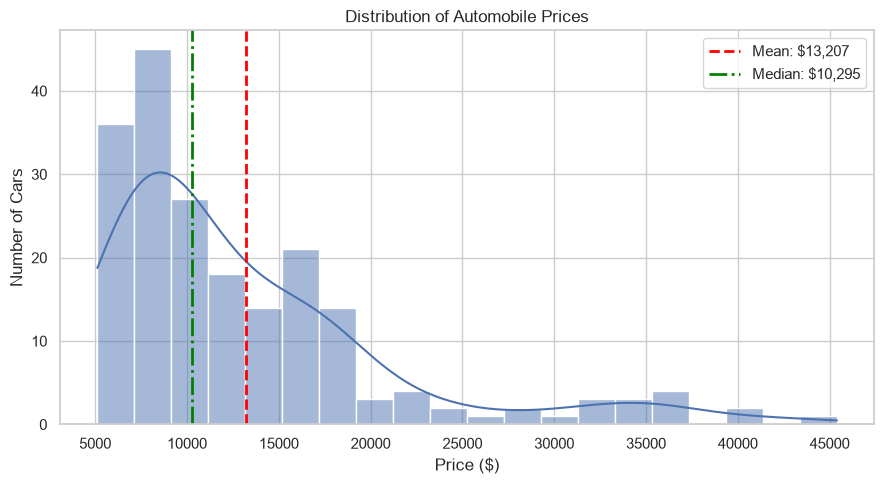

In [36]:

plt.figure(figsize=(9, 5))

# Calculate mean and median
mean_price = df["price"].mean()
median_price = df["price"].median()

# Plot price distribution
sns.histplot(data=df, x="price", bins=20, kde=True)

# Add mean and median lines
plt.axvline(mean_price, color="red", linestyle="--",
            linewidth=2, label=f"Mean: ${mean_price:,.0f}")
plt.axvline(median_price, color="green", linestyle="-.",
            linewidth=2, label=f"Median: ${median_price:,.0f}")

plt.title("Distribution of Automobile Prices")
plt.xlabel("Price ($)")
plt.ylabel("Number of Cars")
plt.legend()
plt.tight_layout()
plt.show()


### Interpretation of the Price Distribution:

The distribution of vehicle prices is right-skewed. The mean price is approximately 13,207$, while the median is 10,295. A relatively small number of expensive vehicles pull the mean upward, making the median a useful measure of a typical vehicle's price in this dataset. 

**Note**: These prices reflect a historical automobile dataset from the 1980s and should not be interpreted as current used-car prices.


### 5. Relationship Between Horsepower and Price

Horsepower is one of the main characteristics we want to investigate. A scatterplot can help us assess whether cars with greater horsepower tend to have higher prices. Each point represents a vehicle with available values for both variables. This analysis identifies an association, not a causal effect.

Cars included in analysis: 199
Pearson correlation: 0.811


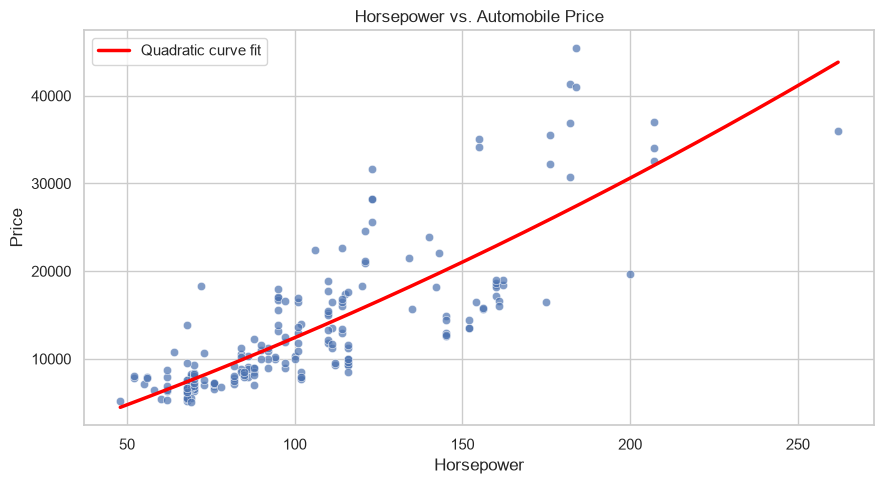

In [10]:

plt.figure(figsize=(9, 5))

# Keep only rows with valid horsepower and price
hp_price = df[["horsepower", "price"]].dropna()

# Calculate Pearson correlation
correlation = hp_price["horsepower"].corr(hp_price["price"])

print("Cars included in analysis:", len(hp_price))
print(f"Pearson correlation: {correlation:.3f}")

# Scatter plot
sns.scatterplot(data=hp_price, x="horsepower", y="price", alpha=0.7)

# Fit a quadratic curve (degree 2)
x = hp_price["horsepower"].astype(float).to_numpy()
y = hp_price["price"].astype(float).to_numpy()

coefficients = np.polyfit(x, y, deg=2)
curve = np.poly1d(coefficients)

# Generate smooth x-values for the fitted curve
x_fit = np.linspace(x.min(), x.max(), 200)
y_fit = curve(x_fit)

# Add curve to plot
plt.plot(x_fit, y_fit, color="red", linewidth=2.5, label="Quadratic curve fit")

plt.title("Horsepower vs. Automobile Price")
plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.legend()
plt.tight_layout()
plt.show()


### Interpretation: Horsepower vs. Price

The scatterplot shows a strong positive relationship between horsepower and automobile price. In general, cars with higher horsepower tend to have higher prices. The Pearson correlation coefficient is approximately 0.811, indicating a strong positive linear association between these two variables.

However, the points do not fall perfectly along a straight line, suggesting that horsepower alone does not explain all price differences. Other factors, such as manufacturer, engine size, vehicle design, and features, may also contribute to automobile prices.

This finding indicates that horsepower is a useful characteristic to consider when comparing cars by price. However, the analysis shows an association rather than causation, and the results are based on a relatively small historical dataset.

### 6. Relationship Between Engine Size and Price

Engine size is another important vehicle characteristic that may be associated with price. Larger engines may be found in more powerful or higher-priced vehicles. A scatterplot and correlation coefficient will help us examine this relationship in the dataset. 

Cars included in analysis: 201
Pearson correlation: 0.872


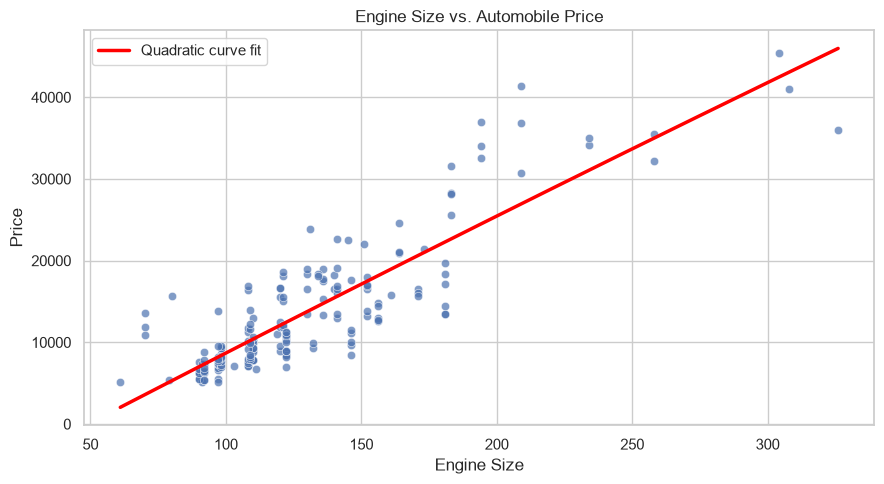

In [11]:

plt.figure(figsize=(9, 5))

# Keep only rows with valid engine size and price
engine_price = df[["engine_size", "price"]].dropna()

# Calculate Pearson correlation
engine_correlation = engine_price["engine_size"].corr( engine_price["price"])

print("Cars included in analysis:", len(engine_price))
print(f"Pearson correlation: {engine_correlation:.3f}")

# Scatter plot
sns.scatterplot( data=engine_price, x="engine_size", y="price", alpha=0.7)

# Fit a quadratic curve (degree 2)
x = engine_price["engine_size"].astype(float).to_numpy()
y = engine_price["price"].astype(float).to_numpy()

coefficients = np.polyfit(x, y, deg=2)
curve = np.poly1d(coefficients)

# Generate smooth x-values for the fitted curve
x_fit = np.linspace(x.min(), x.max(), 200)
y_fit = curve(x_fit)

# Add fitted curve
plt.plot( x_fit, y_fit, color="red", linewidth=2.5, label="Quadratic curve fit")

plt.title("Engine Size vs. Automobile Price")
plt.xlabel("Engine Size")
plt.ylabel("Price")
plt.legend()
plt.tight_layout()
plt.show()


### Interpretation: Engine Size vs. Price

Engine size has a strong positive association with vehicle price (Pearson correlation \(r = 0.872\), based on 201 vehicles with available values). Vehicles with larger engines tend to have higher prices in this dataset. The relationship is not perfect, indicating that other vehicle characteristics also contribute to price differences. This correlation describes an association and does not establish causation.

### 7. Automobile Prices by Manufacturer

Manufacturer is a categorical variable that may be associated with substantial differences in automobile prices. We will compare the number of vehicles and the mean and median price for each manufacturer. Reporting sample sizes is important because some manufacturers have many more observations than others, making comparisons for small groups less reliable. The median is included because the price distribution is right-skewed.

In [12]:
manufacturer_summary = (df.dropna(subset=["price"]) .groupby("make")["price"]
    .agg(car_count="count", median_price="median", mean_price="mean", minimum_price="min",
         maximum_price="max") .sort_values("median_price", ascending=False) .round(2))

display(manufacturer_summary)

,car_count,median_price,mean_price,minimum_price,maximum_price
make,,,,,
jaguar,3,35550.0,34600.00,32250.0,36000.0
porsche,4,33278.0,31400.50,22018.0,37028.0
mercedes-benz,8,32892.0,33647.00,25552.0,45400.0
bmw,8,22835.0,26118.75,16430.0,41315.0
volvo,11,18420.0,18063.18,12940.0,22625.0
audi,6,17580.0,17859.17,13950.0,23875.0
peugot,11,16630.0,15489.09,11900.0,18150.0
mercury,1,16503.0,16503.00,16503.0,16503.0
alfa-romero,3,16500.0,15498.33,13495.0,16500.0


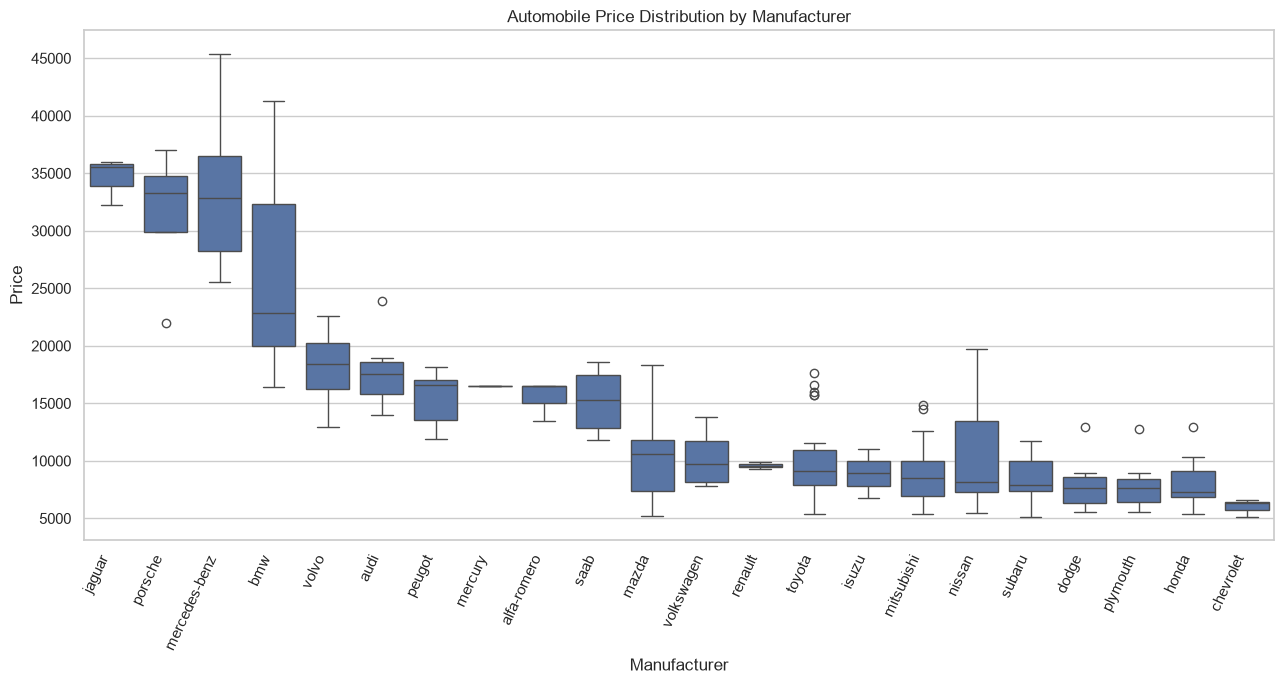

In [13]:
plt.figure(figsize=(13, 7))

manufacturer_order = ( df.groupby("make")["price"] .median().sort_values(ascending=False) .index)

sns.boxplot( data=df, x="make", y="price", order=manufacturer_order)

plt.title("Automobile Price Distribution by Manufacturer")
plt.xlabel("Manufacturer")
plt.ylabel("Price")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

### Interpretation: Automobile Prices by Manufacturer

The manufacturer comparison shows noticeable differences in automobile prices across brands. In this dataset, Jaguar, Porsche, Mercedes-Benz, and BMW are among the manufacturers with the highest median prices, while brands such as Chevrolet, Honda, Dodge, and Plymouth generally have lower median prices.

The boxplot also helps reveal differences in price variability within each manufacturer. Some manufacturers have a wider spread of prices, suggesting that their vehicles differ more substantially in price, while others have a narrower distribution.

The mean and median provide complementary information. When the mean is higher than the median, a few relatively expensive vehicles may be pulling the average upward. The median is particularly useful for comparing typical prices because the overall price distribution is right-skewed.

However, these results should be interpreted cautiously. The number of vehicles varies considerably across manufacturers, and some brands have only a few observations. Their median prices may therefore be less representative of the broader range of vehicles sold by those manufacturers. Furthermore, the differences observed in this historical dataset should not be interpreted as current used-car market prices or as evidence that manufacturer alone determines price.

### 8. Automobile Prices by Body Style

Body style describes the general form of a vehicle, such as a sedan, hatchback, wagon, hardtop, or convertible. Different body styles may serve different needs and may be associated with differences in size, features, and price. We will compare price distributions and sample sizes across body styles to explore these patterns.

In [14]:
body_style_summary = ( df.dropna(subset=["price"]) .groupby("body_style")["price"].agg(
          car_count="count", median_price="median", mean_price="mean", minimum_price="min",
          maximum_price="max") .sort_values("median_price", ascending=False) .round(2))

display(body_style_summary)

,car_count,median_price,mean_price,minimum_price,maximum_price
body_style,,,,,
hardtop,8,19687.5,22208.50,8249.0,45400.0
convertible,6,17084.5,21890.50,11595.0,37028.0
wagon,25,11694.0,12371.96,6918.0,28248.0
sedan,94,11078.5,14459.76,5499.0,41315.0
hatchback,68,8672.0,9957.44,5118.0,22018.0


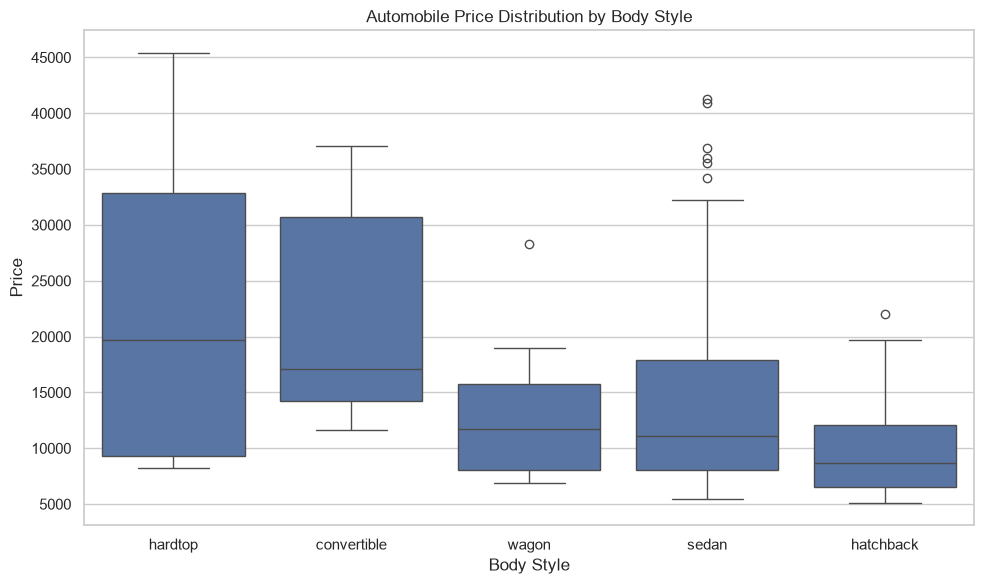

In [15]:
body_order = ( df.groupby("body_style")["price"] .median() .sort_values(ascending=False) .index)

plt.figure(figsize=(10, 6))

sns.boxplot( data=df, x="body_style", y="price", order=body_order)

plt.title("Automobile Price Distribution by Body Style")
plt.xlabel("Body Style")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

### Interpretation: Price by Body Style

The boxplot shows differences in automobile prices across body styles. Convertibles have a relatively high median price of $17,084.50, while hatchbacks have the lowest median price of 8,672. Sedans and other body styles may also differ in their price distributions and variability.

These differences may reflect factors beyond body style, including engine size, horsepower, and manufacturer. Therefore, this comparison is descriptive and does not establish that body style alone explains automobile price differences.

### 9. Automobile Prices by Fuel Type

Fuel type distinguishes gasoline-powered vehicles from diesel-powered vehicles. Fuel type may be associated with price because these vehicles can differ in engine design, performance, and intended use. We will compare price distributions and sample sizes by fuel type. Since the dataset may contain unequal numbers of gasoline and diesel vehicles, group sizes will be considered when interpreting the results.

In [16]:
fuel_summary = ( df.dropna(subset=["price"]).groupby("fuel_type")["price"] .agg( car_count="count",
      median_price="median",  mean_price="mean", minimum_price="min",  maximum_price="max" ) .sort_values("median_price", ascending=False).round(2))

display(fuel_summary)

,car_count,median_price,mean_price,minimum_price,maximum_price
fuel_type,,,,,
diesel,20,13852.5,15838.15,7099.0,31600.0
gas,181,9989.0,12916.41,5118.0,45400.0


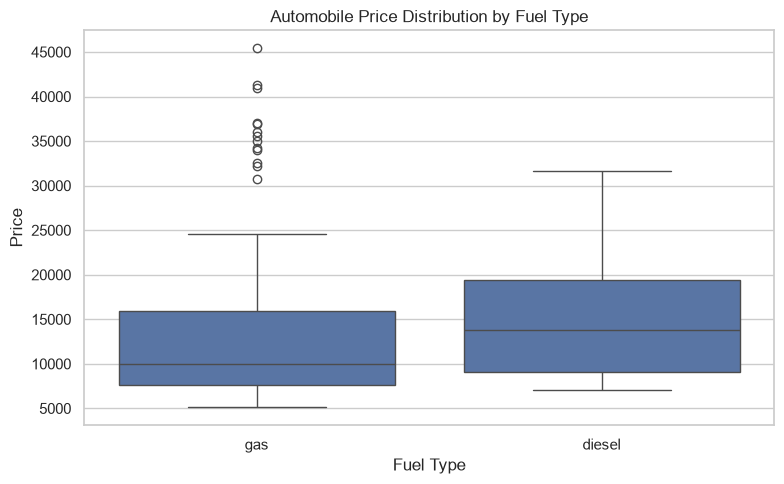

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot( data=df, x="fuel_type", y="price")

plt.title("Automobile Price Distribution by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

### Interpretation: Price by Fuel Type

The summary table compares the number of cars, median price, mean price, minimum price, and maximum price for each fuel type. The boxplot further illustrates differences in price distributions and variability between fuel types.

These differences may be associated with other vehicle characteristics, including engine size, horsepower, body style, and manufacturer. Therefore, this comparison is descriptive and does not establish that fuel type alone explains automobile price differences.

### 10. Automobile Prices by Aspiration Type

Aspiration distinguishes standard engines from turbocharged engines. Turbocharging can increase engine power and may be associated with differences in vehicle performance and price. We will compare the price distributions of standard and turbocharged vehicles while recognizing that other characteristics, such as horsepower, engine size, and manufacturer, may also contribute to any observed differences.

In [18]:
aspiration_summary = ( df.dropna(subset=["price"]) .groupby("aspiration")["price"] .agg( car_count="count", median_price="median", mean_price="mean", minimum_price="min",
          maximum_price="max" ) .sort_values("median_price", ascending=False) .round(2))

display(aspiration_summary)

,car_count,median_price,mean_price,minimum_price,maximum_price
aspiration,,,,,
turbo,36,15686.0,16254.81,7689.0,31600.0
std,165,9538.0,12542.18,5118.0,45400.0


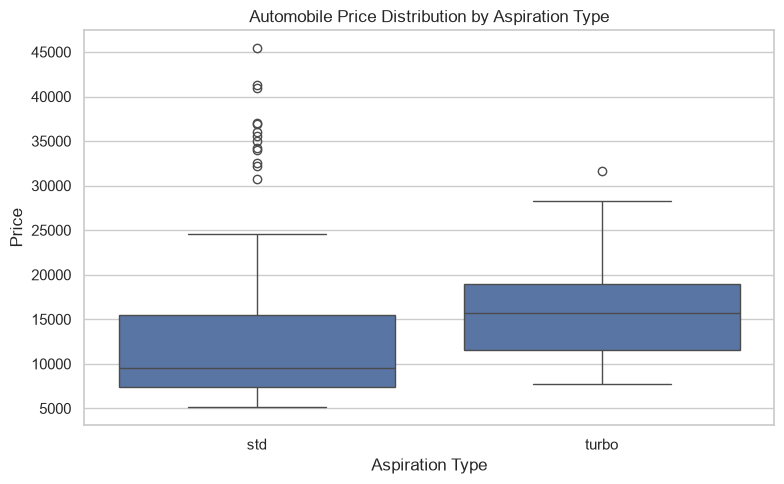

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot( data=df,x="aspiration", y="price")

plt.title("Automobile Price Distribution by Aspiration Type")
plt.xlabel("Aspiration Type")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

### Interpretation: Price by Aspiration Type

Vehicles with turbo aspiration have a higher median price ($15,686) than vehicles with standard aspiration (9,538). This is a descriptive difference. The groups may also differ in horsepower, engine size, manufacturer, and other characteristics, so the comparison does not establish that aspiration type itself causes higher prices.

### 11. Automobile Prices by Drivetrain (transmission system)

The `drive_wheels` variable identifies front-wheel drive (FWD), rear-wheel drive (RWD), and four-wheel drive (4WD). Drivetrain configuration can be associated with vehicle design, performance, and intended use. We will compare price distributions across these categories while considering the number of cars in each group.

In [20]:
drive_summary = ( df.dropna(subset=["price"]) .groupby("drive_wheels")["price"] .agg(  car_count="count",  median_price="median", mean_price="mean", 
                                minimum_price="min", maximum_price="max" ).sort_values("median_price", ascending=False).round(2))

display(drive_summary)

,car_count,median_price,mean_price,minimum_price,maximum_price
drive_wheels,,,,,
rwd,75,16900.0,19757.61,6785.0,45400.0
4wd,8,9005.5,10241.00,7603.0,17450.0
fwd,118,8192.0,9244.78,5118.0,23875.0


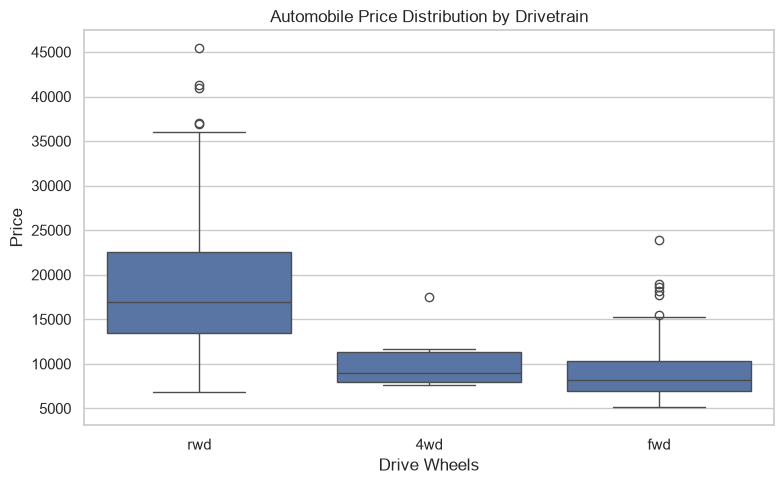

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot( data=df,x="drive_wheels",  y="price", order=drive_summary.index)

plt.title("Automobile Price Distribution by Drivetrain")
plt.xlabel("Drive Wheels")
plt.ylabel("Price")
plt.tight_layout()
plt.show()


### Interpretation: Price by Drivetrain

RWD vehicles have the highest median price ($16,900), followed by 4WD (9,005.50) and FWD vehicles (8,192). Since the 4WD group contains only 8 cars, its results should be interpreted cautiously. Price differences may also reflect factors such as horsepower, engine size, and manufacturer. These findings are descriptive and do not establish causation.

### 12. Automobile Prices by Engine and Vehicle Characteristics

In this section, we are trying to compare automobile price distributions across engine location, number of doors, engine type, and fuel system. 

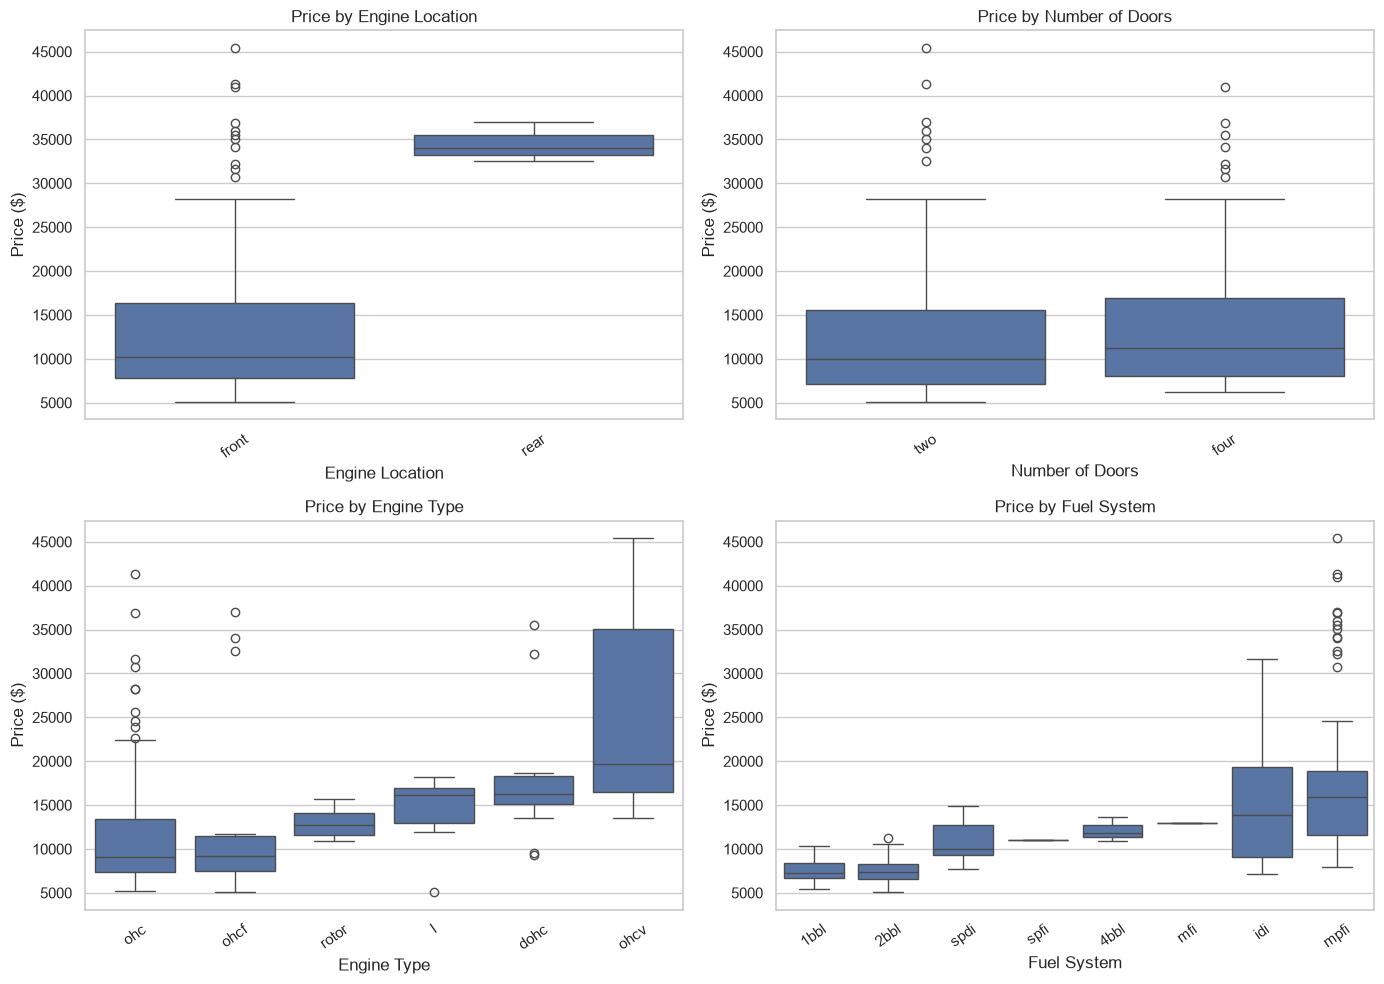

In [22]:

import matplotlib.pyplot as plt
import seaborn as sns

categorical_features = [ ("engine_location", "Engine Location"), ("num_of_doors", "Number of Doors"), ("engine_type", "Engine Type"), ("fuel_system", "Fuel System")]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (feature, title) in zip(axes.flat, categorical_features):
    plot_data = df.dropna(subset=["price", feature])

    # Order categories by median price
    order = (  plot_data.groupby(feature, observed=True)["price"]  .median() .sort_values()   .index )

    sns.boxplot(  data=plot_data, x=feature, y="price",  order=order, ax=ax )

    ax.set_title(f"Price by {title}")
    ax.set_xlabel(title)
    ax.set_ylabel("Price ($)")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


**Interpretation**

The boxplots show differences in vehicle prices across engine location, number of doors, engine type, and fuel system categories. However, these differences should be interpreted cautiously because some categories contain very few vehicles.

Engine location has a particularly small rear-engine group, with only three observations, so its median price may not represent the broader market. Similarly, some engine-type and fuel-system categories have very small sample sizes, making their price distributions less reliable. Although these plots help identify possible patterns, they do not establish that any of these characteristics independently causes higher or lower prices. Other factors, such as engine size, horsepower, and manufacturer, may also contribute to the observed differences.

### 13. Relationships Between Price and Other Numeric Characteristics

Beyond horsepower and engine size, automobile price may be associated with vehicle weight, dimensions, and fuel economy. Heavier or larger vehicles may differ in materials, space, engine requirements, and intended use. Fuel economy may also reflect trade-offs involving vehicle size and performance.

We will examine curb weight, wheelbase, length, width, height, city fuel economy, and highway fuel economy using scatterplots and Pearson correlations. These plots help reveal the direction, strength, and possible nonlinearity of the relationships with price.

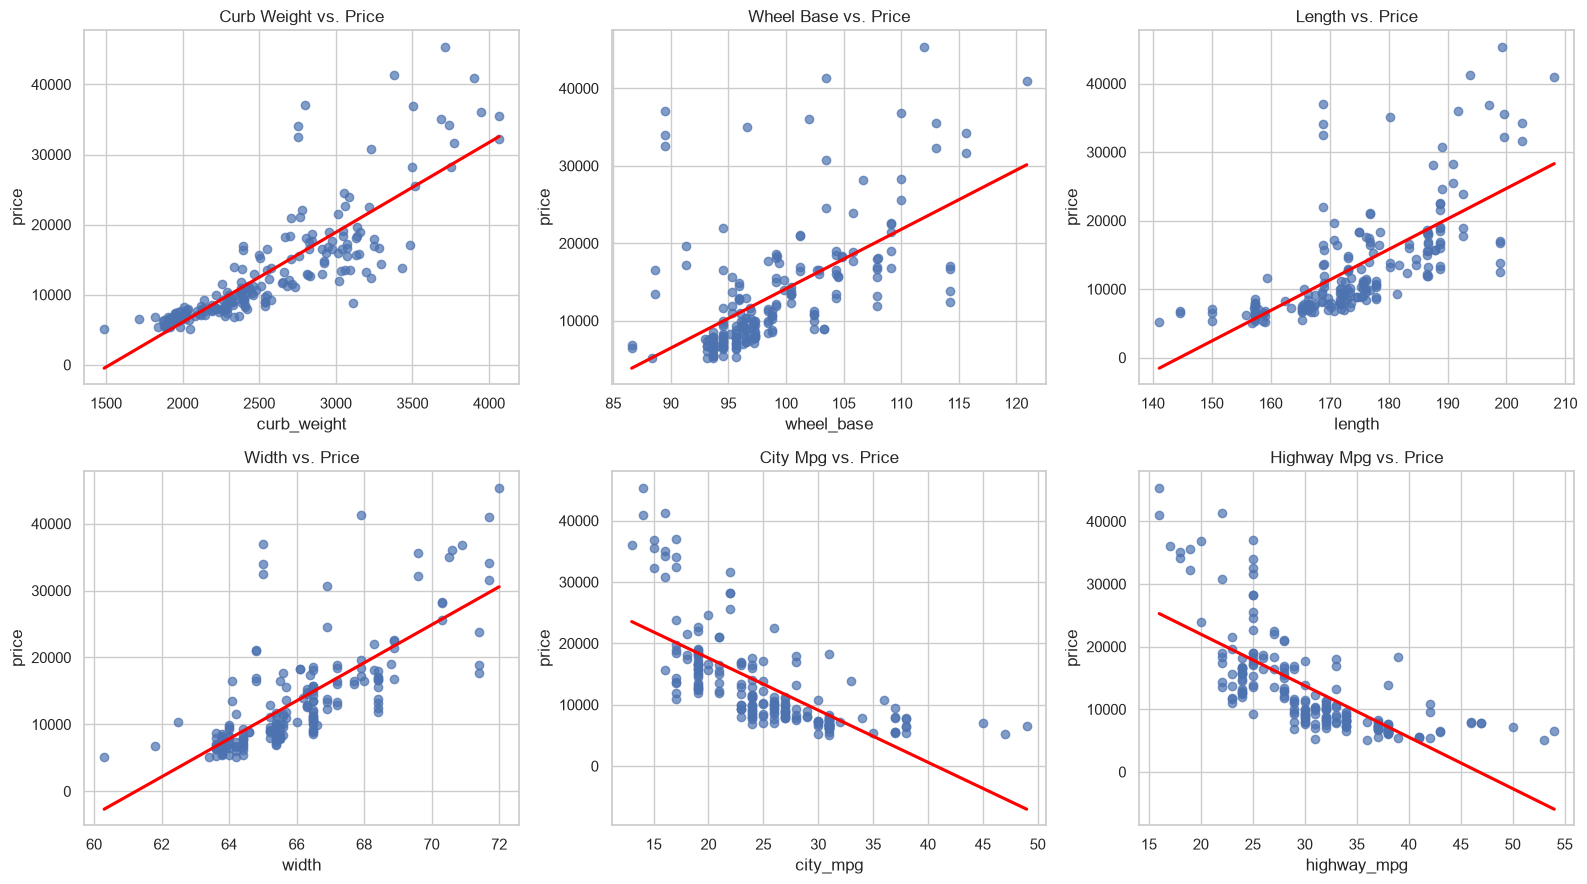

In [23]:
features_to_plot = [ "curb_weight", "wheel_base", "length", "width", "city_mpg", "highway_mpg"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, feature in zip(axes.flat, features_to_plot):
    sns.regplot( data=df, x=feature, y="price", ax=ax, scatter_kws={"alpha": 0.7},  line_kws={"color": "red"}, ci=None)
    ax.set_title(f"{feature.replace('_', ' ').title()} vs. Price")

plt.tight_layout()
plt.show()

### Interpretation: Numeric Characteristics and Price

The correlation analysis shows that automobile price is associated with vehicle weight, dimensions, and fuel economy. Curb weight has a strong positive correlation with price (r = 0.834), followed by width (r = 0.751), length (r = 0.691), and wheelbase (r = 0.585). In contrast, highway MPG (r = -0.705) and city MPG (r = -0.687) have negative correlations with price.

The six scatterplots help illustrate these patterns. An upward trend indicates that larger values of a characteristic tend to accompany higher prices, while a downward trend indicates that larger values tend to accompany lower prices. The strength and consistency of these patterns vary across individual vehicles.

Vehicle weight and dimensions may be associated with price because they reflect differences in vehicle size and design. The negative relationships between fuel economy and price suggest that vehicles with higher fuel economy tend to have lower prices in this dataset. However, these relationships may overlap because weight, dimensions, engine size, horsepower, and fuel economy are correlated with one another.

These results are exploratory. Pearson correlation measures linear association and does not establish causation. It may also fail to capture nonlinear relationships or be influenced by unusual observations. The next step is to examine relationships among predictors to identify overlapping information and interpret the price patterns more carefully.

### 14. Relationships Among Numeric Predictors

Several automobile characteristics may be related to one another. For example, larger engines may be associated with greater horsepower, and heavier vehicles may also have larger dimensions. Examining these relationships helps us understand the structure of the dataset and identify predictors that may provide overlapping information.

We will use a correlation matrix to summarize pairwise linear relationships among numeric variables. Correlation does not establish causation, and the matrix will use available observations for each pair of variables.

In [24]:
correlation_features = [ "price", "horsepower", "engine_size", "curb_weight", "wheel_base", "length", "width", "height","city_mpg", "highway_mpg",
                         "compression_ratio", "peak_rpm",  "bore", "stroke"]

correlation_matrix = df[correlation_features].corr()

display(correlation_matrix.round(2))

,price,horsepower,engine_size,curb_weight,wheel_base,length,width,height,city_mpg,highway_mpg,compression_ratio,peak_rpm,bore,stroke
price,1.00,0.81,0.87,0.83,0.58,0.69,0.75,0.14,-0.69,-0.70,0.07,-0.10,0.54,0.08
horsepower,0.81,1.00,0.81,0.75,0.35,0.56,0.64,-0.11,-0.80,-0.77,-0.21,0.13,0.58,0.09
engine_size,0.87,0.81,1.00,0.85,0.57,0.68,0.74,0.07,-0.65,-0.68,0.03,-0.24,0.59,0.21
curb_weight,0.83,0.75,0.85,1.00,0.78,0.88,0.87,0.30,-0.76,-0.80,0.15,-0.27,0.65,0.17
wheel_base,0.58,0.35,0.57,0.78,1.00,0.87,0.80,0.59,-0.47,-0.54,0.25,-0.36,0.49,0.16
length,0.69,0.56,0.68,0.88,0.87,1.00,0.84,0.49,-0.67,-0.70,0.16,-0.29,0.61,0.13
width,0.75,0.64,0.74,0.87,0.80,0.84,1.00,0.28,-0.64,-0.68,0.18,-0.22,0.56,0.18
height,0.14,-0.11,0.07,0.30,0.59,0.49,0.28,1.00,-0.05,-0.11,0.26,-0.32,0.18,-0.06
city_mpg,-0.69,-0.80,-0.65,-0.76,-0.47,-0.67,-0.64,-0.05,1.00,0.97,0.32,-0.11,-0.59,-0.04
highway_mpg,-0.70,-0.77,-0.68,-0.80,-0.54,-0.70,-0.68,-0.11,0.97,1.00,0.27,-0.05,-0.59,-0.04


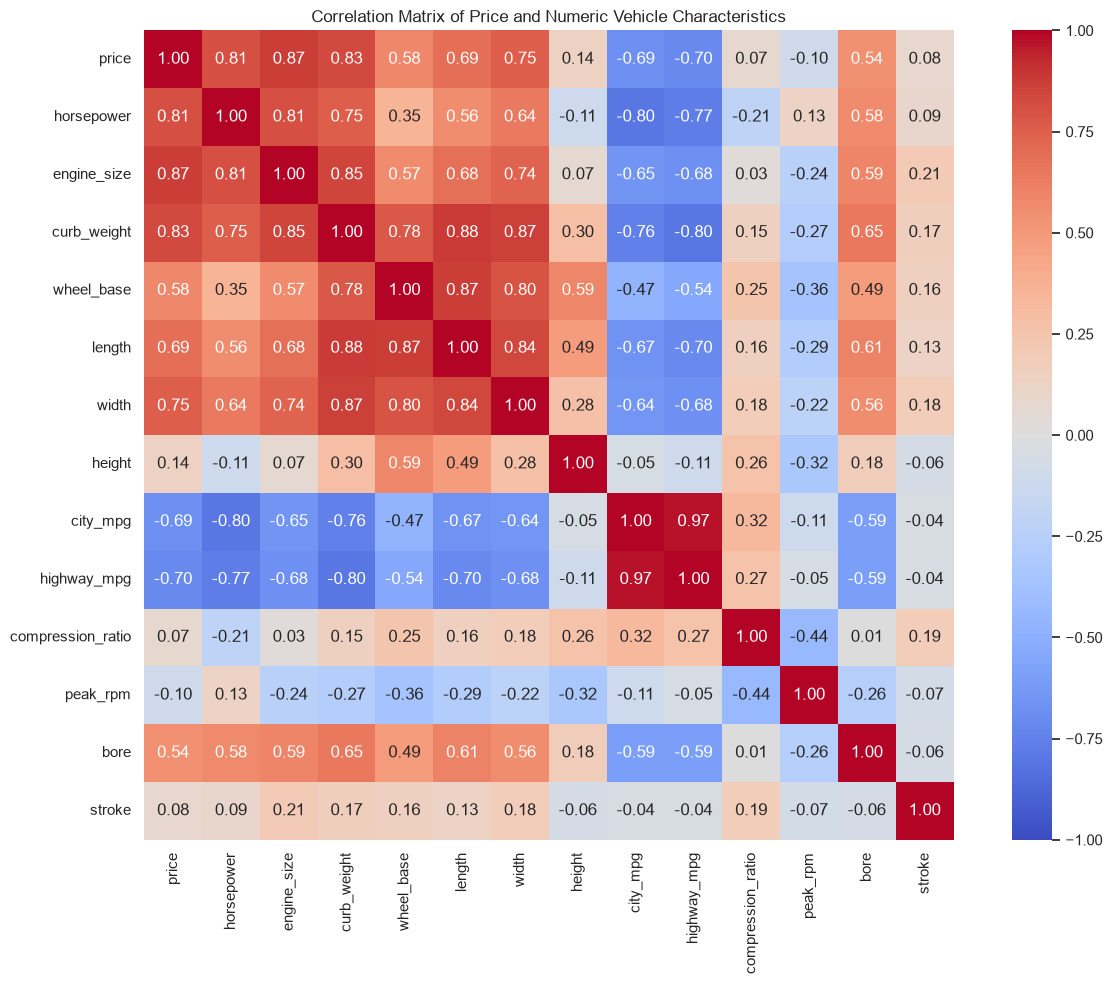

In [25]:
plt.figure(figsize=(13, 10))

sns.heatmap( correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm",  center=0, vmin=-1, vmax=1,  square=True)

plt.title("Correlation Matrix of Price and Numeric Vehicle Characteristics")
plt.tight_layout()
plt.show()


### Interpretation: Correlation Matrix

The correlation matrix shows the strength and direction of relationships between price and numeric vehicle characteristics. The color scale ranges from **−1 to +1**: **red** indicates positive correlation (both variables tend to increase together), while **blue** indicates negative correlation (one tends to decrease as the other increases). **White or very light colors** indicate weak or near-zero correlation. The darker the color, the stronger the relationship. Strong correlations with price may identify vehicle characteristics associated with higher or lower prices.


### 15. Strongest Relationships Among Numeric Predictors

This part identifies the 10 strongest correlations between numeric vehicle characteristics, excluding price, to reveal overlapping information among predictors.


In [26]:
predictor_correlations = ( correlation_matrix .drop(index="price", columns="price"))

upper_triangle = predictor_correlations.where(   np.triu(np.ones(predictor_correlations.shape), k=1).astype(bool))

strongest_pairs = (  upper_triangle.stack()  .rename("correlation")  .reset_index()  .rename(columns={      "level_0": "Variable 1",      "level_1": "Variable 2"  }))

strongest_pairs["Absolute Correlation"] = (   strongest_pairs["correlation"].abs())

strongest_pairs = strongest_pairs.sort_values(    "Absolute Correlation",    ascending=False)

display(strongest_pairs.head(10).reset_index(drop=True).round(3))

,Variable 1,Variable 2,correlation,Absolute Correlation
0,city_mpg,highway_mpg,0.971,0.971
1,curb_weight,length,0.878,0.878
2,wheel_base,length,0.875,0.875
3,curb_weight,width,0.867,0.867
4,engine_size,curb_weight,0.851,0.851
5,length,width,0.841,0.841
6,horsepower,engine_size,0.811,0.811
7,horsepower,city_mpg,-0.804,0.804
8,curb_weight,highway_mpg,-0.797,0.797
9,wheel_base,width,0.795,0.795


### Interpretation: Relationships Among Predictors

City and highway MPG have the strongest correlation (r = 0.971), while curb weight is strongly correlated with vehicle length (r = 0.878) and width (r = 0.867). Engine size and horsepower are also strongly related (r = 0.811). These relationships suggest that some predictors provide overlapping information. 

### 16. Outlier Assessment

Outliers are observations that fall unusually far from the rest of a variable's distribution. They may represent legitimate high-performance or luxury vehicles rather than data errors. We will use the interquartile range (IQR) rule to flag potentially unusual values in price, horsepower, engine size, curb weight, and city fuel economy. These flags are intended for investigation; observations will not be removed automatically.

In [27]:
# Identify potential outliers using the 1.5 × IQR rule

outlier_columns = [ "price", "horsepower", "engine_size", "curb_weight",  "city_mpg"]

outlier_rows = []

for column in outlier_columns:
    values = pd.to_numeric(df[column], errors="coerce").dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = ( (values < lower_bound) | (values > upper_bound)).sum()

    outlier_rows.append({ "Variable": column,  "Valid observations": len(values),  "Lower bound": lower_bound, "Upper bound": upper_bound,"Potential outliers": int(outlier_count)})

outlier_summary = pd.DataFrame(outlier_rows).set_index("Variable")

display(outlier_summary.round(2))


,Valid observations,Lower bound,Upper bound,Potential outliers
Variable,,,,
price,201,-5312.5,29587.5,14
horsepower,203,1.0,185.0,6
engine_size,205,31.0,207.0,10
curb_weight,205,960.0,4120.0,0
city_mpg,205,2.5,46.5,2



### Interpretation of Potential Outliers

The IQR rule identifies observations that fall outside the typical range for each variable. These observations are potential outliers, not necessarily data errors. In a vehicle dataset, unusually high prices, horsepower, or engine sizes may reflect legitimate luxury or performance vehicles. Potential outliers are therefore retained for the subsequent analysis rather than removed automatically. However, they may influence summary statistics and correlations, so results should be interpreted with this possibility in mind.


### 17. Summary of Numeric Relationships with Price

To compare the numeric characteristics consistently, we summarize their Pearson correlations with price in one table. This helps identify which characteristics have the strongest positive and negative linear associations with price. Correlations are descriptive and do not measure independent effects when predictors are related to one another.

In [28]:
# Summarize numeric correlations with price and valid pair counts

numeric_features = [ "engine_size", "curb_weight", "horsepower", "width", "highway_mpg", "length", "city_mpg", "wheel_base",
    "bore", "height", "peak_rpm", "stroke", "compression_ratio"]

correlation_rows = []

for feature in numeric_features:
    valid_pairs = df[[feature, "price"]].dropna()
    correlation = valid_pairs[feature].corr(valid_pairs["price"])

    correlation_rows.append({   "Variable": feature,  "Correlation with Price": correlation, "Valid Pair Count": len(valid_pairs),  "Absolute Correlation": abs(correlation)  })

price_correlation_summary = (  pd.DataFrame(correlation_rows)  .sort_values("Absolute Correlation", ascending=False) .reset_index(drop=True))

display(price_correlation_summary.round(3).style.hide(axis="index"))


Variable,Correlation with Price,Valid Pair Count,Absolute Correlation
engine_size,0.872000,201,0.872000
curb_weight,0.834000,201,0.834000
horsepower,0.811000,199,0.811000
width,0.751000,201,0.751000
highway_mpg,-0.705000,201,0.705000
length,0.691000,201,0.691000
city_mpg,-0.687000,201,0.687000
wheel_base,0.585000,201,0.585000
bore,0.543000,197,0.543000
height,0.135000,201,0.135000


### Interpretation: Summary of Numeric Correlations with Price

Engine size has the strongest positive correlation with price (r = 0.872), followed by curb weight (r = 0.834) and horsepower (r = 0.811). Highway MPG (r = -0.705) and city MPG (r = -0.687) have the strongest negative correlations with price. These results suggest that larger, heavier, and more powerful vehicles tend to have higher prices in this dataset, while vehicles with better fuel economy tend to have lower prices. The number of valid pairs varies by variable because some observations are missing. These correlations describe associations, not causal relationships, and correlated predictors may share overlapping information.

### 18. Numeric imputation evaluation with a held-out test set
This replaces the original random-masking evaluation loop. For each target with missing values, it holds out a subset of rows with observed target values, masks that target in the test rows, and fits preprocessing/imputation on the training rows only. It reports MAE and RMSE in the target's original units. This remains a small, single-split evaluation, so the results can vary by split.

In [29]:
# Numeric imputation evaluation: held-out test rows, no test-data leakage

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge

# 1. Preserve numeric predictors and exclude price
df_original = df.copy(deep=True)

numeric_predictor_cols = ( df_original.select_dtypes(include="number") .columns.drop("price")  .tolist())

X_numeric = df_original[numeric_predictor_cols].copy()

# Define the columns that actually contain missing values
numeric_missing_cols = [ col for col in X_numeric.columns  if X_numeric[col].isna().any()]

print("Numeric columns with missing values:")
print(X_numeric[numeric_missing_cols].isna().sum())

# 2. Define candidate imputation methods
imputation_methods = {  "Mean": SimpleImputer(strategy="mean"), "Median": SimpleImputer(strategy="median"), "KNN (k=5)": KNNImputer(n_neighbors=5),
    "BayesianRidge Iterative": IterativeImputer(    estimator=BayesianRidge(),    max_iter=10,    random_state=42 )}

# 3. Evaluate methods using a held-out set for each target variable
evaluation_results = []

for target in numeric_missing_cols:
    # Only observed target values can be used as evaluation answers
    observed_indices = X_numeric.index[    X_numeric[target].notna()].to_numpy()

    if len(observed_indices) < 5:
        print(f"Skipping {target}: too few observed values.")
        continue

    # Hold out 20% of observed values
    train_indices, test_indices = train_test_split( observed_indices,  test_size=0.20,  random_state=42 )

    # Training data excludes the test rows.
    # Rows with naturally missing target values may remain in training.
    X_train = X_numeric.drop(index=test_indices).copy()
    X_test = X_numeric.loc[test_indices].copy()

    # Save true values and mask the target in the test data
    y_true = X_test[target].copy()
    X_test.loc[:, target] = np.nan

    # Fit the scaler ONLY on training rows
    scaler_eval = StandardScaler()
    X_train_scaled = pd.DataFrame(  scaler_eval.fit_transform(X_train), columns=numeric_predictor_cols,index=X_train.index )
    X_test_scaled = pd.DataFrame(  scaler_eval.transform(X_test),  columns=numeric_predictor_cols,  index=X_test.index )

    # Fit each imputer ONLY on the scaled training data
    for method_name, method in imputation_methods.items():
        fitted_imputer = clone(method)

        train_imputed = fitted_imputer.fit_transform(X_train_scaled)
        test_imputed = fitted_imputer.transform(X_test_scaled)

        # Convert test estimates back to the original units
        test_imputed_original = scaler_eval.inverse_transform(    test_imputed)

        imputed_test_df = pd.DataFrame(  test_imputed_original,  columns=numeric_predictor_cols, index=X_test.index )

        y_pred = imputed_test_df[target]

        mae = mean_absolute_error(y_true, y_pred)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))

        evaluation_results.append({  "Variable": target,   "Method": method_name,   "Test Values": len(test_indices),   "MAE": mae,    "RMSE": rmse })

# 4. Compare methods
imputation_comparison = pd.DataFrame(evaluation_results)

if not imputation_comparison.empty:
    imputation_comparison = (   imputation_comparison   .sort_values(["Variable", "RMSE"])    .reset_index(drop=True)  )
    display(imputation_comparison.round(3))
else:
    print("No imputation evaluation results were produced.")


Numeric columns with missing values:
normalized_losses    41
bore                  4
stroke                4
horsepower            2
peak_rpm              2
dtype: int64


,Variable,Method,Test Values,MAE,RMSE
0,bore,KNN (k=5),41,0.115,0.151
1,bore,BayesianRidge Iterative,41,0.147,0.174
2,bore,Mean,41,0.236,0.270
3,bore,Median,41,0.237,0.272
4,horsepower,BayesianRidge Iterative,41,11.276,13.816
5,horsepower,KNN (k=5),41,13.678,17.820
6,horsepower,Mean,41,32.989,41.671
7,horsepower,Median,41,33.537,43.673
8,normalized_losses,KNN (k=5),33,16.739,26.887
9,normalized_losses,BayesianRidge Iterative,33,22.357,29.198


In [30]:
# Preserve the original data for comparison
df_original = df.copy(deep=True)

missing_before = pd.DataFrame({ "Missing Count": df_original.isna().sum(), "Missing Percent": (df_original.isna().mean() * 100).round(2)})

missing_before = missing_before[  missing_before["Missing Count"] > 0].sort_values("Missing Count", ascending=False)

display(missing_before)

,Missing Count,Missing Percent
normalized_losses,41,20.00
bore,4,1.95
stroke,4,1.95
price,4,1.95
num_of_doors,2,0.98
horsepower,2,0.98
peak_rpm,2,0.98


In [32]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# Select numeric predictors and exclude price
numeric_predictor_cols = df_original.select_dtypes( include="number").columns.drop("price").tolist()

# Preserve the original values for comparison
X_numeric = df_original[numeric_predictor_cols].copy()

print("Number of numeric predictors:", len(numeric_predictor_cols))
print("\nNumeric predictors:")
print(numeric_predictor_cols)

print("\nMissing values in numeric predictors:")
print(X_numeric.isna().sum().loc[lambda x: x > 0])

Number of numeric predictors: 15

Numeric predictors:
['symboling', 'normalized_losses', 'wheel_base', 'length', 'width', 'height', 'curb_weight', 'engine_size', 'bore', 'stroke', 'compression_ratio', 'horsepower', 'peak_rpm', 'city_mpg', 'highway_mpg']

Missing values in numeric predictors:
normalized_losses    41
bore                  4
stroke                4
horsepower            2
peak_rpm              2
dtype: int64


In [33]:
# Standardize numeric predictors while preserving missing values
scaler = StandardScaler()

X_scaled = pd.DataFrame(  scaler.fit_transform(X_numeric),   columns=numeric_predictor_cols,   index=X_numeric.index)

# Apply KNN imputation using the 5 nearest neighbors
knn_imputer = KNNImputer(n_neighbors=5, weights="uniform")
X_knn_scaled = knn_imputer.fit_transform(X_scaled)

# Convert the imputed values back to the original measurement scales
X_knn = pd.DataFrame(  scaler.inverse_transform(X_knn_scaled),   columns=numeric_predictor_cols,  index=X_numeric.index)

# Create a separate dataset with KNN-imputed numeric predictors
df_knn = df_original.copy(deep=True)
df_knn[numeric_predictor_cols] = X_knn

print("Missing values after KNN imputation:")
print(df_knn[numeric_predictor_cols].isna().sum().loc[   lambda x: x > 0])

print("\nFirst five imputed values for normalized_losses:")
display( df_knn.loc[  df_original["normalized_losses"].isna(),   ["normalized_losses", "horsepower", "engine_size", "curb_weight"]  ].head())

Missing values after KNN imputation:
Series([], dtype: int64)

First five imputed values for normalized_losses:


,normalized_losses,horsepower,engine_size,curb_weight
0,171.8,111.0,130.0,2548.0
1,171.8,111.0,130.0,2548.0
2,136.2,154.0,152.0,2823.0
5,130.8,110.0,136.0,2507.0
7,159.8,110.0,136.0,2954.0


In [34]:

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge

# Regression-based iterative imputation using Bayesian Ridge
regression_imputer = IterativeImputer(estimator=BayesianRidge(), max_iter=10,random_state=42, skip_complete=True)
X_regression_scaled = regression_imputer.fit_transform(X_scaled)

# Convert estimates back to the original measurement scales
X_regression = pd.DataFrame(  scaler.inverse_transform(X_regression_scaled), columns=numeric_predictor_cols, index=X_numeric.index)
df_regression = df_original.copy(deep=True)
df_regression[numeric_predictor_cols] = X_regression

# Iterative imputation using the default estimator
iterative_imputer = IterativeImputer(  max_iter=10, random_state=42)
X_iterative_scaled = iterative_imputer.fit_transform(X_scaled)

# Convert estimates back to the original measurement scales
X_iterative = pd.DataFrame( scaler.inverse_transform(X_iterative_scaled), columns=numeric_predictor_cols, index=X_numeric.index)
df_iterative = df_original.copy(deep=True)
df_iterative[numeric_predictor_cols] = X_iterative

print("Regression-based imputation complete.")
print("Iterative imputation complete.")
print(  "Missing numeric predictor values after regression-based imputation:",   df_regression[numeric_predictor_cols].isna().sum().sum())
print( "Missing numeric predictor values after iterative imputation:", df_iterative[numeric_predictor_cols].isna().sum().sum())


Regression-based imputation complete.
Iterative imputation complete.
Missing numeric predictor values after regression-based imputation: 0
Missing numeric predictor values after iterative imputation: 0


### Interpretation of Imputation Method Comparison


KNN achieved the lowest RMSE for normalized losses, bore, stroke, and peak RPM. BayesianRidge iterative imputation performed best for horsepower. These results are preliminary because they use a single train-test split, and artificially masked values may differ from naturally missing data.
Overall, KNN appears promising, but no single method is best for every variable.

## 19. Conclusion

### 1. Engine Size Is Strongly Associated with Price
Engine size had the strongest positive correlation with automobile price (\(r = 0.872\)), suggesting that cars with larger engines generally had higher prices in this dataset.

### 2. Vehicle Weight and Horsepower Also Matter
Curb weight (\(r = 0.834\)) and horsepower (\(r = 0.811\)) were also strongly positively correlated with price, indicating that vehicle size and performance were important characteristics associated with price differences.

### 3. KNN Was the Best Imputation Method for Most Tested Variables
KNN achieved the lowest RMSE for normalized losses, bore, stroke, and peak RPM. BayesianRidge iterative imputation performed best for horsepower. These results come from a single held-out evaluation split.

### 4. Findings Have Important Limitations
The dataset contains only 205 vehicles from the 1980s. Missing values, unequal category sizes, correlated predictors, and unavailable information such as mileage and vehicle condition limit how broadly the findings can be applied. The results show associations, not causation.

## 20. Limitations

**Historical, small dataset:** The 205 records represent automobiles from the 1980s, not today's used-car market.

**Missing values:** Missing observations reduce the sample size available for some analyses. Imputation estimates may differ from actual values.

**Unequal category sizes:** Categories with few vehicles have less stable summary statistics.

**Potential outliers:** Unusual vehicles may influence means, correlations, and trends.

**Correlated predictors:** Engine size, horsepower, weight, and dimensions share overlapping information.

**Unmeasured factors:** Mileage, vehicle condition, maintenance, accident history, and location are unavailable.

**Imputation evaluation limits:** The comparison uses one held-out split, and artificially masked values may differ from naturally missing values.




### 21. AI-use disclosure: 

I used ChatGPT to assist with coding, debugging, and building the app.